# MSDI Analysis: the published method

**Aim.** Build the Multivariate Standardized Drought Index (MSDI) for one district by the published method of
Karunarathne, De Silva and Perera (2024), which follows Hao and AghaKouchak (2013); read it against the paper's Table 4
cut-offs, the same for every district; and record what the method does on this data.

Every number comes from the project's modules (`msdi_analysis.py`, `thresholds.py`, `index_data.py`, `compare_indices.py`,
`model_checks.py`, `demo_random_subset_tau.py`) and the saved fits in `cache/msdi_fits.pkl`, as on the dashboard.

**Contents**
1. The method in three equations
2. Data: rainfall and ground temperature
3. Marginal distributions
4. Pairing the data: u and v
5. Dependence between rainfall and temperature
6. Copula selection
7. MSDI calculation
8. The index is not standardised
9. Thresholds
   - 9a. Table 4 on this data
   - 9b. Drought events
10. Known issues of the published method
    - 10a. The shuffle demonstration
    - 10b. The direction check
    - 10c. The seasonal cycle
11. Agreement with SPI and SSI
12. Sensitivity checks
    - 12a. The copula family
    - 12b. T2M instead of TS
13. All 25 districts
14. What this means
15. Summary of findings
16. Limitations

**How to run.** Open from the project folder, change the settings cell if needed, then *Restart and Run All*
(about half a minute). The fits are read from `cache/msdi_fits.pkl`; run `py -3.12 run_msdi_all_districts.py` first if
that file is missing.

In [1]:
# Load the helpers, move to the project folder and apply the dashboard look
import nbtools as nt
nt.setup()

import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import common
import theme

import msdi_analysis as M
import thresholds as TH
import compare_indices as CI
import index_data
import model_checks as mc
import demo_random_subset_tau as demo

## Settings

In [2]:
DISTRICT = "Anuradhapura"        # any of the 25 districts
T = 3                            # main prolonged period in months: 3, 6, 9 or 12
TEMP_COL = M.TEMP_COL            # "ts", the paper's ground temperature (NASA POWER earth skin temperature)
START_YEAR, END_YEAR = 1984, 2025  # years shown in the time-series plots
N_SHUFFLE = 1000                 # random-subset draws in the shuffle demonstration

CACHE = M.load_model_cache(common.CACHE_DIR / "msdi_fits.pkl")
model = CACHE[M.model_key(DISTRICT, TEMP_COL)]
paper_point = CACHE[M.model_key("Paper point", TEMP_COL)]
s = model.series
print(f"Loaded the {DISTRICT} model ({TEMP_COL.upper()}, {len(s)} months, bootstrap size {model.n_boot}).")
print(f"Table 4 cut-offs at T = {T}: extremely dry at or below {TH.cutoff(T)[0]}, dry at or below {TH.cutoff(T)[1]}.")

Loaded the Anuradhapura model (TS, 504 months, bootstrap size 500).
Table 4 cut-offs at T = 3: extremely dry at or below -3.2, dry at or below -1.3.


## 1. The method in three equations

Hao and AghaKouchak (2013) turned the joint probability of two drought variables into one normal score. Karunarathne, De Silva
and Perera (2024) borrow that idea for rainfall $X$ and temperature $Y$ in North Central Province, join them with a copula $C$,
and average the score over a prolonged period $T$. These are equations 6, 7 and 8 of their paper.

$$p = P(X \le x,\ Y \le y) = C\big(F_X(x), F_Y(y)\big)$$

$$\text{MSDI} = \Phi^{-1}(p)$$

$$\text{T-month MSDI} = \frac{1}{T}\sum_{k=1}^{T} \text{1-month MSDI}_k,\qquad T \in \{3, 6, 9, 12\}$$

The marginals and the copula are fitted as in the paper, on all months pooled. Rainfall and temperature are paired month
by month, as the first equation requires. The index is capped at $\pm 5$ (paper Sec. 3).

## 2. Data: rainfall and ground temperature

Rainfall is the monthly average in mm/day (PRECTOTCORR, the paper's unit), with zero months set to $10^{-10}$ as in the
note to the paper's Table 2. Temperature is NASA POWER **TS**, earth skin temperature, which is what the paper's "ground
temperature" turns out to be, as the check below shows. T2M, air at 2 m, is plotted for comparison.

$$\bar x_{y,m} = \frac{\text{monthly total (mm)}}{\text{days in month}}\quad(\text{mm/day})$$

,Year,Month,rain (mm),rain (mm/day),T2M (degC),TS (degC)
0,1984,1,355.260,11.460,23.950,23.820
1,1984,2,326.250,11.250,24.240,24.140
2,1984,3,169.415,5.465,25.005,24.965
3,1984,4,301.050,10.035,25.975,26.010
4,1984,5,47.895,1.545,26.375,26.330
5,1984,6,22.050,0.735,25.735,25.685


,series at the paper's point,min (degC),max (degC)
0,paper's figure 2,22.98,33.74
1,NASA POWER TS,22.98,33.75
2,NASA POWER T2M,22.98,31.41


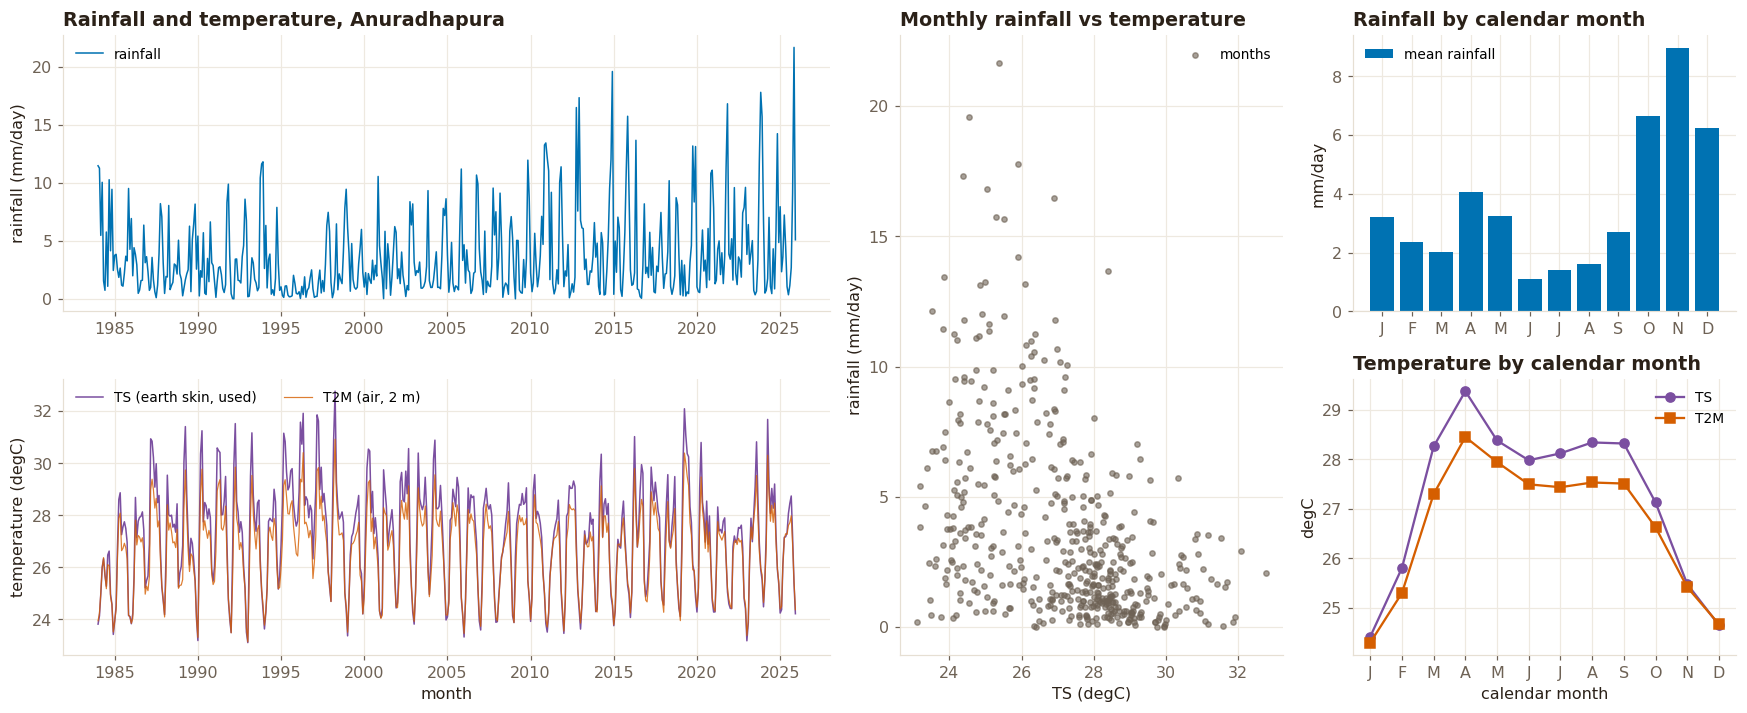

<span style='color:#6E6255'>*Rainfall comes in two monsoon bursts and temperature has its own seasonal cycle: both stay in the data, because the method pools all months.*</span>

In [3]:
df = M.load_inputs(DISTRICT)                       # Year, Month, prcp, rain, t2m, ts
df["Date"] = pd.to_datetime(df[["Year", "Month"]].assign(day=1))
nt.show(df[["Year", "Month", "prcp", "rain", "t2m", "ts"]].rename(
    columns={"prcp": "rain (mm)", "rain": "rain (mm/day)", "t2m": "T2M (degC)", "ts": "TS (degC)"}), n=6)

# Which NASA POWER temperature is the paper's? It reports 22.98 to 33.74 degC at its point.
pt = M.load_paper_point()
nt.show(pd.DataFrame([{"series at the paper's point": "paper's figure 2", "min (degC)": 22.98, "max (degC)": 33.74},
                      {"series at the paper's point": "NASA POWER TS", "min (degC)": pt["ts"].min(), "max (degC)": pt["ts"].max()},
                      {"series at the paper's point": "NASA POWER T2M", "min (degC)": pt["t2m"].min(), "max (degC)": pt["t2m"].max()}]), 2)

view = df[(df["Year"] >= START_YEAR) & (df["Year"] <= END_YEAR)]
fig = plt.figure(figsize=(16, 6.6))
gs = fig.add_gridspec(2, 3, width_ratios=[2, 1, 1])
a1 = fig.add_subplot(gs[0, 0]); a2 = fig.add_subplot(gs[1, 0], sharex=a1)
a3 = fig.add_subplot(gs[:, 1]); a4 = fig.add_subplot(gs[0, 2]); a5 = fig.add_subplot(gs[1, 2])
a1.plot(view["Date"], view["rain"], color=theme.INDEX_COLOURS["SPI"], lw=1, label="rainfall")
a1.set_title(f"Rainfall and temperature, {DISTRICT}"); a1.set_ylabel("rainfall (mm/day)"); a1.legend(loc="upper left")
a2.plot(view["Date"], view["ts"], color=theme.INDEX_COLOURS["MSDI"], lw=1, label="TS (earth skin, used)")
a2.plot(view["Date"], view["t2m"], color=theme.INDEX_COLOURS["SSI"], lw=0.8, alpha=0.8, label="T2M (air, 2 m)")
a2.set_xlabel("month"); a2.set_ylabel("temperature (degC)"); a2.legend(loc="upper left", ncol=2)
a3.scatter(df[TEMP_COL], df["rain"], s=12, color=theme.MUTED, alpha=0.6, label="months")
a3.set_title("Monthly rainfall vs temperature"); a3.set_xlabel(f"{TEMP_COL.upper()} (degC)"); a3.set_ylabel("rainfall (mm/day)"); a3.legend()
cl = df.groupby("Month")[["rain", "t2m", "ts"]].mean()
mon = [calendar.month_abbr[m][0] for m in range(1, 13)]
a4.bar(cl.index, cl["rain"], color=theme.INDEX_COLOURS["SPI"], label="mean rainfall")
a4.set_xticks(range(1, 13), mon); a4.set_title("Rainfall by calendar month"); a4.set_ylabel("mm/day"); a4.legend()
a5.plot(cl.index, cl["ts"], marker="o", color=theme.INDEX_COLOURS["MSDI"], label="TS")
a5.plot(cl.index, cl["t2m"], marker="s", color=theme.INDEX_COLOURS["SSI"], label="T2M")
a5.set_xticks(range(1, 13), mon); a5.set_title("Temperature by calendar month"); a5.set_xlabel("calendar month")
a5.set_ylabel("degC"); a5.legend()
plt.tight_layout(); plt.show()
nt.caption("Rainfall comes in two monsoon bursts and temperature has its own seasonal cycle: both stay in the data, because the method pools all months.")

#### Interpretation

In [4]:
raw_r = stats.spearmanr(df["rain"], df[TEMP_COL]).statistic
hot, cool = cl[TEMP_COL].idxmax(), cl[TEMP_COL].idxmin()
nt.interpret(f"""
TS at the paper's point runs from {pt['ts'].min():.2f} to {pt['ts'].max():.2f} degC against the paper's 22.98 to 33.74, while T2M stops at
{pt['t2m'].max():.2f}, so the paper's "ground temperature" is **TS**, and the notebook uses it. In {DISTRICT} the hottest month is
{calendar.month_name[hot]} ({cl.loc[hot, TEMP_COL]:.1f} degC) and the coolest {calendar.month_name[cool]} ({cl.loc[cool, TEMP_COL]:.1f} degC), and monthly rainfall and
temperature have a rank correlation of **{raw_r:+.2f}**. The method does not remove this seasonal cycle, which matters in section 10c.
""")


TS at the paper's point runs from 22.98 to 33.75 degC against the paper's 22.98 to 33.74, while T2M stops at
31.41, so the paper's "ground temperature" is **TS**, and the notebook uses it. In Anuradhapura the hottest month is
April (29.4 degC) and the coolest January (24.4 degC), and monthly rainfall and
temperature have a rank correlation of **-0.48**. The method does not remove this seasonal cycle, which matters in section 10c.


## 3. Marginal distributions

Each variable gets one distribution for all months. Rainfall is the lowest AIC of the paper's Table 2 candidates,
four-parameter Beta, Gamma and Half-Gaussian. Temperature is a two-component Gaussian mixture fitted by EM from a k-means
start (paper eq. 2).

$$\text{AIC} = 2k - 2\ln L,\qquad F_Y(y) = \sum_{i=1}^{2} w_i\,\Phi\Big(\frac{y-\mu_i}{\sigma_i}\Big)$$

As in the paper, $k$ counts every parameter: Beta 4, Gamma 3, Half-Gaussian 2.

Rainfall, Anuradhapura (n = 504)


,distribution,parameters,k,log L,AIC
0,gamma,"shape=1.027, loc=-0.0004293, scale=3.539",3,-1154.28,2314.56
1,beta,"alpha=0.7686, beta=3.683, lower=0, range=21.87",4,-1163.08,2334.16
2,halfnorm,"loc=0, sigma=5.107",2,-1187.61,2379.22


Rainfall, NASA POWER at the paper's point, 1981-2021, next to the paper's Table 2


,distribution,parameters,k,log L,AIC,AIC in the paper
0,gamma,"shape=1.139, loc=-0.00533, scale=3.151",3,-1118.30,2242.59,2104.17
1,beta,"alpha=0.7917, beta=3.721, lower=0, range=20.92",4,-1122.29,2252.58,2061.75
2,halfnorm,"loc=0, sigma=4.886",2,-1137.63,2279.26,2265.90


Temperature, Anuradhapura


,model,fit,k,log L,BIC
0,two-component mixture,"0.207*N(24.473, 0.630) + 0.793*N(27.895, 1.558)",5,-1031.2,2093.50
1,one normal,"1.000*N(27.188, 1.982)",2,-1059.9,2132.25


Paper's mixture at its point: 0.31*N(24.859, 0.801) + 0.69*N(28.659, 1.319). Ours at that point: 0.176*N(24.363, 0.599) + 0.824*N(27.564, 1.627)


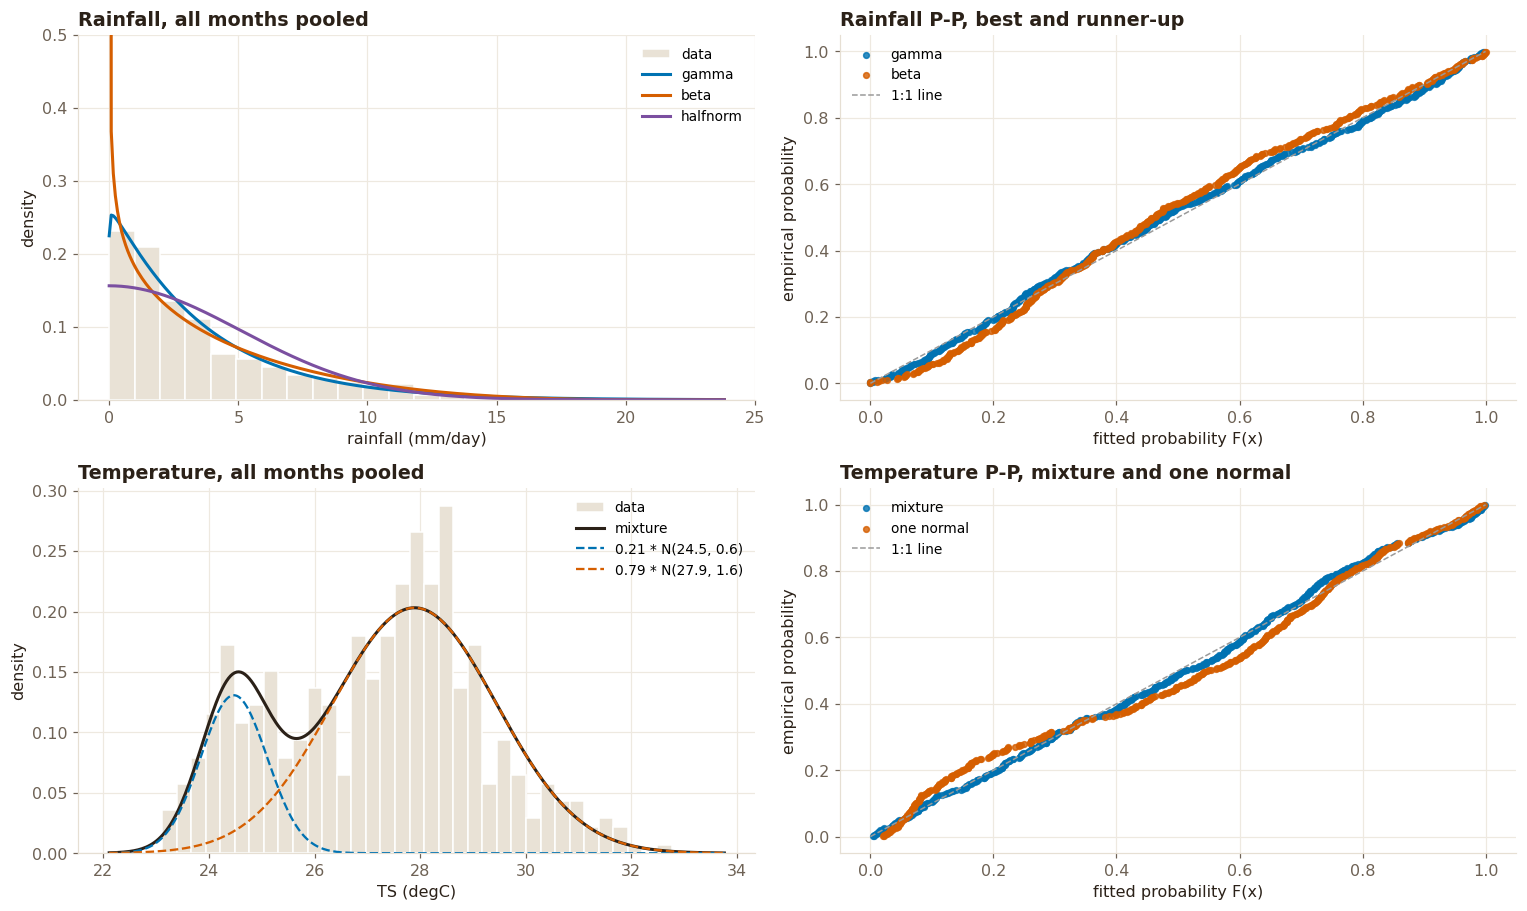

<span style='color:#6E6255'>*Top: rainfall. Bottom: temperature, whose two peaks are the two seasons. Points on the dashed line mean a good fit.*</span>

In [5]:
def rain_table(m):
    """The fitted rainfall distributions of one model, best first."""
    return pd.DataFrame([{"distribution": f.family, "parameters": f.describe(), "k": f.k, "log L": f.loglik, "AIC": f.aic}
                         for f in sorted(m.rain_fits, key=lambda f: f.aic)])

print(f"Rainfall, {DISTRICT} (n = {len(s)})"); nt.show(rain_table(model), 2)
PAPER_TABLE2 = {"beta": 2061.749, "gamma": 2104.167, "halfnorm": 2265.897}
at_point = rain_table(paper_point).assign(**{"AIC in the paper": lambda t: t["distribution"].map(PAPER_TABLE2)})
print("Rainfall, NASA POWER at the paper's point, 1981-2021, next to the paper's Table 2"); nt.show(at_point, 2)
gmm_tab = pd.DataFrame([{"model": "two-component mixture", "fit": model.gmm.describe(), "k": model.gmm.k, "log L": model.gmm.loglik, "BIC": model.gmm.bic},
                        {"model": "one normal", "fit": model.normal.describe(), "k": model.normal.k, "log L": model.normal.loglik, "BIC": model.normal.bic}])
print(f"Temperature, {DISTRICT}"); nt.show(gmm_tab, 2)
print(f"Paper's mixture at its point: 0.31*N(24.859, 0.801) + 0.69*N(28.659, 1.319). Ours at that point: {paper_point.gmm.describe()}")

frozen = {f.family: f.dist(*f.params) for f in model.rain_fits}
order = [f.family for f in sorted(model.rain_fits, key=lambda f: f.aic)]
tg = np.linspace(s["temp"].min() - 1, s["temp"].max() + 1, 300)
fig, ax = plt.subplots(2, 2, figsize=(14, 8.4))
nt.hist_with_fits(ax[0, 0], s["rain"], frozen, order, "Rainfall, all months pooled", "rainfall (mm/day)")
ax[0, 0].set_ylim(0, 0.5)
nt.pp_plot(ax[0, 1], s["rain"], {order[0]: frozen[order[0]], order[1]: frozen[order[1]]}, "Rainfall P-P, best and runner-up")
ax[1, 0].hist(s["temp"], bins=35, density=True, color="#E9E2D6", edgecolor="white", label="data")
ax[1, 0].plot(tg, model.gmm.pdf(tg), color=theme.INK, lw=2, label="mixture")
for w, mu, sd, c in zip(model.gmm.weights, model.gmm.means, model.gmm.sds, (theme.INDEX_COLOURS["SPI"], theme.INDEX_COLOURS["SSI"])):
    ax[1, 0].plot(tg, w * stats.norm.pdf(tg, mu, sd), color=c, ls="--", label=f"{w:.2f} * N({mu:.1f}, {sd:.1f})")
ax[1, 0].set_title("Temperature, all months pooled"); ax[1, 0].set_xlabel(f"{TEMP_COL.upper()} (degC)"); ax[1, 0].set_ylabel("density"); ax[1, 0].legend()
nt.pp_plot(ax[1, 1], s["temp"], {"mixture": model.gmm, "one normal": model.normal}, "Temperature P-P, mixture and one normal")
plt.tight_layout(); plt.show()
nt.caption("Top: rainfall. Bottom: temperature, whose two peaks are the two seasons. Points on the dashed line mean a good fit.")

#### Interpretation

In [6]:
gap = {f.family: f.aic for f in paper_point.rain_fits}
n_gamma = sum(CACHE[M.model_key(d, TEMP_COL)].rain.family == "gamma" for d in common.list_districts())
nt.interpret(f"""
In {DISTRICT} the lowest AIC is **{model.rain.family}** ({model.rain.aic:.1f}), and Gamma wins in {n_gamma} of the 25 districts. That differs from the
paper, which found Beta best. At the paper's own point, with the NASA POWER data used here, AIC is {gap['gamma']:.1f} for Gamma and {gap['beta']:.1f} for
Beta, against 2104.2 and 2061.7 in Table 2. So Table 2 could not be reproduced, and on this data its conclusion that Gamma fits this rainfall poorly
does not hold. The rainfall itself differs: its maximum here is {M.load_paper_point()['rain'].max():.2f} mm/day, against 18.41 in the paper. The mixture ({model.gmm.describe()}) is better than one normal by
{model.normal.bic - model.gmm.bic:.1f} BIC points, so the paper's bimodal temperature does hold, as a result of pooling two seasons.
""")


In Anuradhapura the lowest AIC is **gamma** (2314.6), and Gamma wins in 25 of the 25 districts. That differs from the
paper, which found Beta best. At the paper's own point, with the NASA POWER data used here, AIC is 2242.6 for Gamma and 2252.6 for
Beta, against 2104.2 and 2061.7 in Table 2. So Table 2 could not be reproduced, and on this data its conclusion that Gamma fits this rainfall poorly
does not hold. The rainfall itself differs: its maximum here is 20.71 mm/day, against 18.41 in the paper. The mixture (0.207*N(24.473, 0.630) + 0.793*N(27.895, 1.558)) is better than one normal by
38.7 BIC points, so the paper's bimodal temperature does hold, as a result of pooling two seasons.


## 4. Pairing the data: u and v

Each month's rainfall and temperature go through their fitted distributions, and the two probabilities stay side by side
for the same month. The table join on year and month in `msdi_analysis.load_inputs` is what guarantees this.

$$u = F_X(x),\qquad v = F_Y(y)$$

In [7]:
EX = s.loc[s[f"MSDI{T}"].idxmin()]                  # worked month: the lowest MSDI-T on record
EX_NAME = f"{calendar.month_name[int(EX['Month'])]} {int(EX['Year'])}"
pairs = s[["Year", "Month", "rain", "temp", "u", "v"]].rename(columns={"rain": "rain (mm/day)", "temp": f"{TEMP_COL.upper()} (degC)"})
nt.show(pairs, 4, n=6)
print("Worked month:")
nt.show(pairs[(s["Year"] == EX["Year"]) & (s["Month"] == EX["Month"])], 4)

,Year,Month,rain (mm/day),TS (degC),u,v
0,1984,1,11.460,23.820,0.9586,0.0346
1,1984,2,11.250,24.140,0.9561,0.0680
2,1984,3,5.465,24.965,0.7781,0.1855
3,1984,4,10.035,26.010,0.9383,0.2950
4,1984,5,1.545,26.330,0.3410,0.3314
5,1984,6,0.735,25.685,0.1775,0.2630


Worked month:


,Year,Month,rain (mm/day),TS (degC),u,v
98,1992,3,0.0,29.94,0.0001,0.9249


#### Interpretation

In [8]:
nt.interpret(f"""
The worked month is **{EX_NAME}**, the lowest MSDI-{T} on record. Its rainfall of {EX['rain']:.2f} mm/day gives u = {EX['u']:.4f}, and its
temperature of {EX['temp']:.2f} degC gives v = {EX['v']:.4f}. Both distributions pool all months, so u and v compare this month with every month of the
year, not with the same calendar month in other years. A low v can therefore simply mean that it is the cool season.
""")


The worked month is **March 1992**, the lowest MSDI-3 on record. Its rainfall of 0.00 mm/day gives u = 0.0001, and its
temperature of 29.94 degC gives v = 0.9249. Both distributions pool all months, so u and v compare this month with every month of the
year, not with the same calendar month in other years. A low v can therefore simply mean that it is the cool season.


## 5. Dependence between rainfall and temperature

Kendall's tau and Spearman's rho of the month-paired $(u, v)$ say how rainfall and temperature move together. Tau decides
which copula families are possible.

$$\tau = \frac{n_c - n_d}{\binom{n}{2}},\qquad \rho_S = 1 - \frac{6\sum d_i^2}{n(n^2-1)}$$

,pair,Kendall tau,Spearman rho
0,"(u, v), all months",-0.324,-0.475
1,"(u, v), mean within calendar months",-0.357,NaN
2,paper's reported value,-0.007,NaN


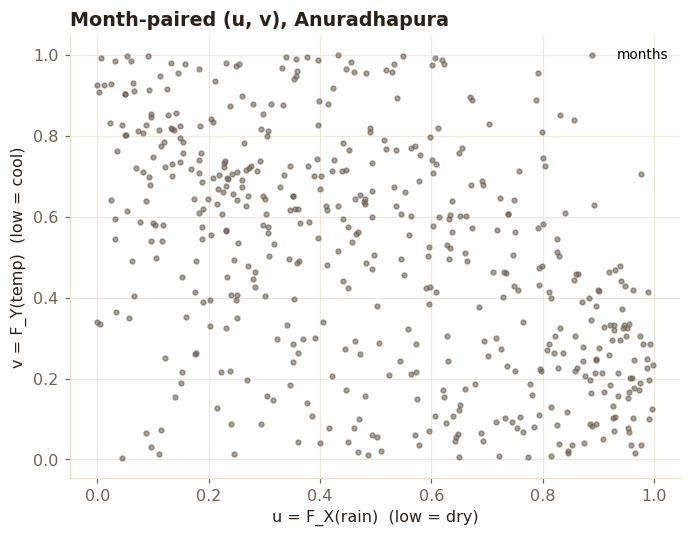

<span style='color:#6E6255'>*The cloud falls from top left to bottom right: dry months are mostly hot, wet months mostly cool.*</span>

In [9]:
within = pd.Series({m: stats.kendalltau(g["u"], g["v"]).statistic for m, g in s.groupby("Month")})
dep = pd.DataFrame([{"pair": "(u, v), all months", "Kendall tau": model.kendall_tau, "Spearman rho": model.spearman_rho},
                    {"pair": "(u, v), mean within calendar months", "Kendall tau": within.mean(), "Spearman rho": np.nan},
                    {"pair": "paper's reported value", "Kendall tau": demo.PAPER_TAU, "Spearman rho": np.nan}])
nt.show(dep)
fig, ax = plt.subplots(figsize=(6.4, 5))
ax.scatter(s["u"], s["v"], s=10, color=theme.MUTED, alpha=0.6, label="months")
ax.set_title(f"Month-paired (u, v), {DISTRICT}"); ax.set_xlabel("u = F_X(rain)  (low = dry)"); ax.set_ylabel("v = F_Y(temp)  (low = cool)"); ax.legend()
plt.tight_layout(); plt.show()
nt.caption("The cloud falls from top left to bottom right: dry months are mostly hot, wet months mostly cool.")

#### Interpretation

In [10]:
nt.interpret(f"""
With months paired, Kendall's tau is **{model.kendall_tau:+.3f}** (Spearman {model.spearman_rho:+.3f}), far from the paper's {demo.PAPER_TAU:+.4f}; section 10a
shows why. Inside a single calendar month it averages {within.mean():+.3f}, {'at least as strong' if abs(within.mean()) >= abs(model.kendall_tau) else 'weaker than the overall value, but still clear'}, so the link is not only a matter of
the seasons: in a given month of the year, a drier year also tends to be a hotter one.
""")


With months paired, Kendall's tau is **-0.324** (Spearman -0.475), far from the paper's -0.0071; section 10a
shows why. Inside a single calendar month it averages -0.357, at least as strong, so the link is not only a matter of
the seasons: in a given month of the year, a drier year also tends to be a hotter one.


## 6. Copula selection

The paper's Table 3 candidates are Frank, FGM and AMH. Gaussian, Gumbel and Clayton are added as extra candidates. Each
family is fitted by maximum likelihood, and the lowest AIC wins among those whose range includes the sample tau.

$$\text{Frank: } C=-\tfrac1\theta\ln\!\Big(1+\tfrac{(e^{-\theta u}-1)(e^{-\theta v}-1)}{e^{-\theta}-1}\Big)$$

$$\text{FGM: } C=uv\,[1+\theta(1-u)(1-v)],\ |\tau|\le\tfrac29\qquad
\text{AMH: } C=\frac{uv}{1-\theta(1-u)(1-v)},\ -0.182\le\tau\le\tfrac13$$

$$\text{Gaussian: } C=\Phi_2\big(\Phi^{-1}(u),\Phi^{-1}(v);\rho\big)\qquad
\text{Gumbel, Clayton: } \tau\ge0$$

The Cramer-von Mises statistic $S_n=\sum[C_n-C_\theta]^2$ with its bootstrap p-value is reported, not used. RMSE is
$\sqrt{\tfrac1n\sum(C_n-C_\theta)^2}$.

,family,tau range,theta,log L,AIC,BIC,RMSE,CvM p,usable,selected,note
0,Frank,-1.000 to +1.000,-3.1787,61.7393,-121.4786,-117.2561,0.0098,0.011,True,yes,
1,FGM,-0.222 to +0.222,NaN,NaN,NaN,NaN,NaN,NaN,False,,tau = -0.324 is outside this family's range (-...
2,AMH,-0.182 to +0.333,NaN,NaN,NaN,NaN,NaN,NaN,False,,tau = -0.324 is outside this family's range (-...
3,Gaussian,-1.000 to +1.000,-0.4271,50.7560,-99.5120,-95.2894,0.0135,0.001,True,,
4,Gumbel,+0.000 to +1.000,NaN,NaN,NaN,NaN,NaN,NaN,False,,tau = -0.324 is outside this family's range (0...
5,Clayton,+0.000 to +1.000,NaN,NaN,NaN,NaN,NaN,NaN,False,,tau = -0.324 is outside this family's range (0...


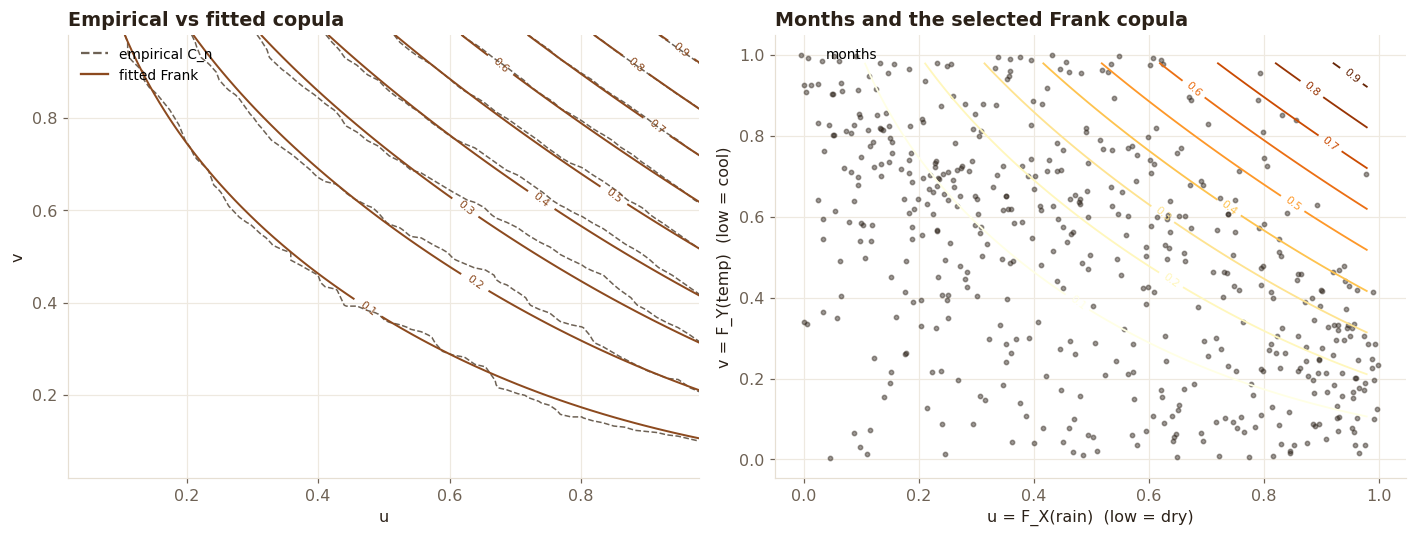

<span style='color:#6E6255'>*Close dashed and solid contours mean the copula reproduces the observed dependence.*</span>

In [11]:
cop = mc.msdi_copula_table(model)
nt.show(cop.drop(columns=["lambda_U", "lambda_L"]), 4)
g = np.linspace(0.02, 0.98, 60); GU, GV = np.meshgrid(g, g)
fitted = M.copula_cdf(model.best_family, GU.ravel(), GV.ravel(), model.best_theta).reshape(GU.shape)
emp = mc.empirical_copula_grid(s["u"].values, s["v"].values, g)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
lv = np.arange(0.1, 1, 0.1)
ax[0].contour(g, g, emp, levels=lv, colors=theme.MUTED, linestyles="--", linewidths=1)
c = ax[0].contour(GU, GV, fitted, levels=lv, colors=theme.ACCENT, linewidths=1.3); ax[0].clabel(c, fontsize=7)
ax[0].plot([], [], color=theme.MUTED, ls="--", label="empirical C_n"); ax[0].plot([], [], color=theme.ACCENT, label=f"fitted {model.best_family}")
ax[0].set_title("Empirical vs fitted copula"); ax[0].set_xlabel("u"); ax[0].set_ylabel("v"); ax[0].legend(loc="upper left")
c = ax[1].contour(GU, GV, fitted, levels=lv, cmap="YlOrBr", linewidths=1.2); ax[1].clabel(c, fontsize=7)
ax[1].scatter(s["u"], s["v"], s=8, color=theme.INK, alpha=0.45, label="months")
ax[1].set_title(f"Months and the selected {model.best_family} copula"); ax[1].set_xlabel("u = F_X(rain)  (low = dry)")
ax[1].set_ylabel("v = F_Y(temp)  (low = cool)"); ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()
nt.caption("Close dashed and solid contours mean the copula reproduces the observed dependence.")

#### Interpretation

In [12]:
sel = cop[cop["selected"] == "yes"].iloc[0]
nt.interpret(f"""
With tau = {model.kendall_tau:+.3f}, only {', '.join(cop.loc[cop['usable'], 'family'])} can be fitted: {', '.join(cop.loc[~cop['usable'], 'family'])} cannot reach it. The selected copula is
**{sel['family']}** (theta {sel['theta']:.3f}, AIC {sel['AIC']:.1f}, RMSE {sel['RMSE']:.4f}). The paper's FGM was possible only because its tau was near zero. The bootstrap test gives
p = {sel['CvM p']:.3f}, {'so the test rejects this copula at the 5% level, which no rule here acts on' if sel['CvM p'] < 0.05 else 'so the test does not reject it'}. One copula for all months has to average two seasons, which
is probably why.
""")


With tau = -0.324, only Frank, Gaussian can be fitted: FGM, AMH, Gumbel, Clayton cannot reach it. The selected copula is
**Frank** (theta -3.179, AIC -121.5, RMSE 0.0098). The paper's FGM was possible only because its tau was near zero. The bootstrap test gives
p = 0.011, so the test rejects this copula at the 5% level, which no rule here acts on. One copula for all months has to average two seasons, which
is probably why.


## 7. MSDI calculation

Each month's $(u, v)$ gives a joint probability, a normal score and, over $T$ months, a mean.

$$p = C(u, v),\qquad \text{MSDI} = \Phi^{-1}(p),\qquad \text{T-month MSDI} = \frac{1}{T}\sum_{k=1}^{T}\text{1-month MSDI}_k$$

,month,u,v,"p = C(u, v)",MSDI = Phi^-1(p),mean of last 3,MSDI-3 stored,class
0,March 1992,0.0001,0.9249,0.0001,-3.7974,-3.5351,-3.5351,Extremely dry


Last 3 one-month values: -3.462, -3.346, -3.797


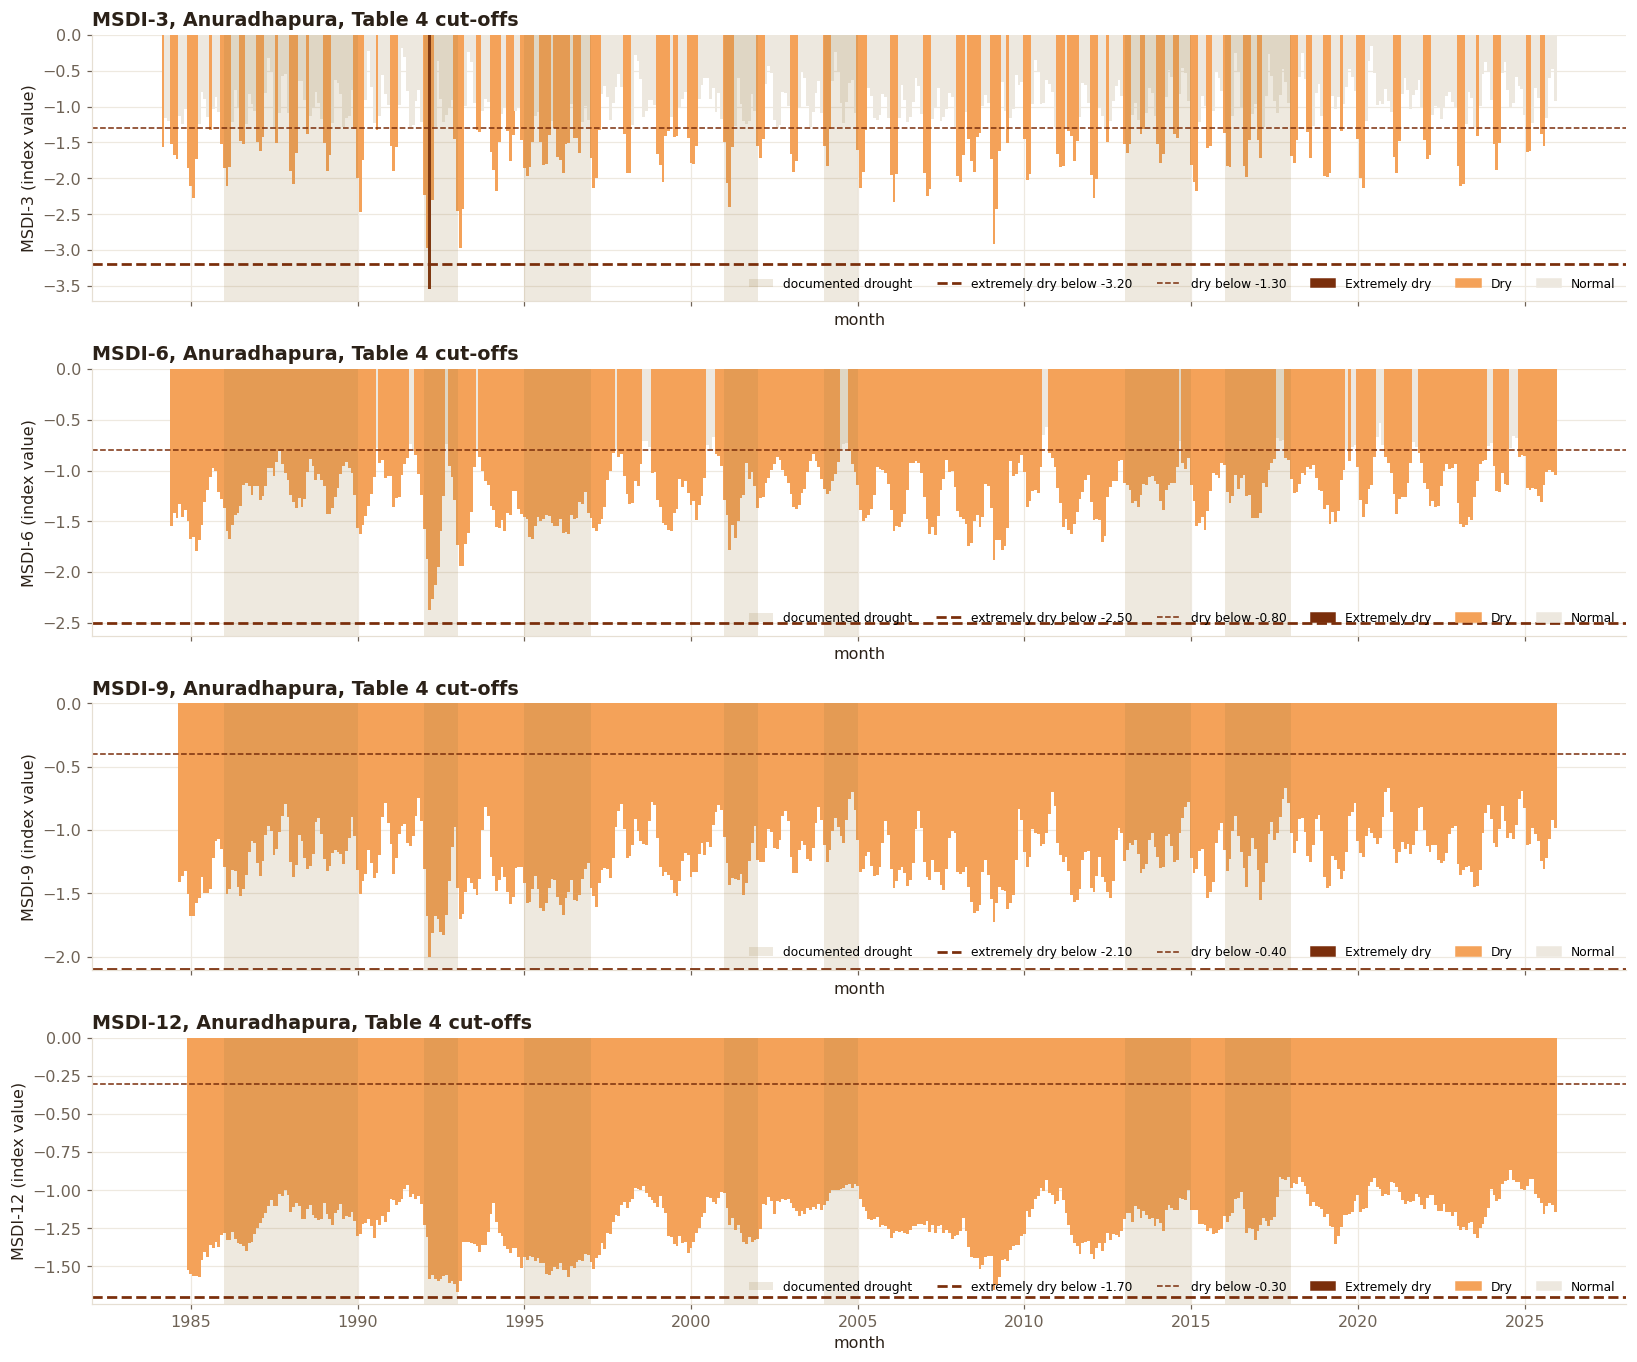

<span style='color:#6E6255'>*Like the paper's Figure 7. Dashed lines are the cut-offs and shaded bands the documented droughts.*</span>

In [13]:
i = EX.name
last = s["MSDI1"].iloc[i - T + 1:i + 1]
extreme, dry = TH.cutoff(T)
work = pd.DataFrame([{"month": EX_NAME, "u": EX["u"], "v": EX["v"], "p = C(u, v)": EX["p"], "MSDI = Phi^-1(p)": EX["MSDI1"],
                      f"mean of last {T}": last.mean(), f"MSDI-{T} stored": EX[f"MSDI{T}"],
                      "class": TH.classify(pd.Series([EX[f"MSDI{T}"]]), extreme, dry).iloc[0]}])
nt.show(work, 4)
print(f"Last {T} one-month values:", ", ".join(f"{v:.3f}" for v in last))

fig, ax = plt.subplots(4, 1, figsize=(15, 12.5), sharex=True)
for a, k in zip(ax, TH.T_SCALES):
    sv = s.dropna(subset=[f"MSDI{k}"])
    sv = sv[(sv["Year"] >= START_YEAR) & (sv["Year"] <= END_YEAR)]
    ce, cd = TH.cutoff(k)
    nt.msdi_bars(a, pd.to_datetime(sv[["Year", "Month"]].assign(day=1)), sv[f"MSDI{k}"], TH.classify(sv[f"MSDI{k}"], ce, cd),
                 ce, cd, f"MSDI-{k}, {DISTRICT}, Table 4 cut-offs", f"MSDI-{k}")
plt.tight_layout(); plt.show()
nt.caption("Like the paper's Figure 7. Dashed lines are the cut-offs and shaded bands the documented droughts.")

#### Interpretation

In [14]:
nt.interpret(f"""
In {EX_NAME}, p = C({EX['u']:.4f}, {EX['v']:.4f}) = {EX['p']:.4f}, so the one-month MSDI is Phi^-1({EX['p']:.4f}) = **{EX['MSDI1']:.2f}**. The mean of the last {T} one-month values
gives **MSDI-{T} = {EX[f'MSDI{T}']:.2f}**, the same as the stored value, so the worked example matches the dashboard. Against the Table 4 cut-offs ({extreme:.2f} and {dry:.2f}) that is
**{work['class'].iloc[0]}**. A longer T averages more months, so the series narrows: that is why the paper's cut-offs rise with T.
""")


In March 1992, p = C(0.0001, 0.9249) = 0.0001, so the one-month MSDI is Phi^-1(0.0001) = **-3.80**. The mean of the last 3 one-month values
gives **MSDI-3 = -3.54**, the same as the stored value, so the worked example matches the dashboard. Against the Table 4 cut-offs (-3.20 and -1.30) that is
**Extremely dry**. A longer T averages more months, so the series narrows: that is why the paper's cut-offs rise with T.


## 8. The index is not standardised

$\Phi^{-1}(p)$ would be $N(0, 1)$ only if $p$ were uniform, but a joint probability is not. Even with no dependence at all,
$p = uv$ has mean 0.25, so the index sits well below 0.

$$E[C(U, V)] = 0.25\ \text{ under independence},\qquad \bar z \ne 0$$

,T,mean,SD,% months below 0,% months <= -1
0,1,-1.210,0.758,96.429,57.937
1,3,-1.208,0.511,99.603,60.913
2,6,-1.210,0.282,99.008,74.206
3,9,-1.209,0.232,98.413,79.563
4,12,-1.209,0.167,97.817,87.698


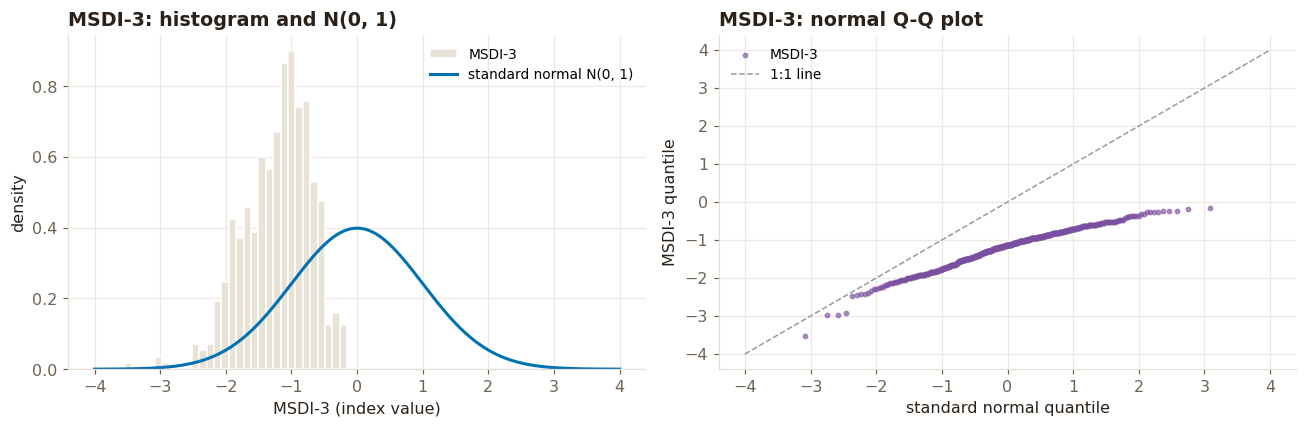

<span style='color:#6E6255'>*A standardised index would follow the blue curve and the dashed line. This one sits to the left of both.*</span>

In [15]:
nrm = pd.DataFrame([{"T": k, "mean": s[f"MSDI{k}"].mean(), "SD": s[f"MSDI{k}"].std(), "% months below 0": 100 * (s[f"MSDI{k}"] < 0).mean(),
                     "% months <= -1": 100 * (s[f"MSDI{k}"] <= -1).mean()} for k in M.ALL_SCALES])
nt.show(nrm)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
nt.normal_check(ax, s[f"MSDI{T}"], f"MSDI-{T}")
ax[0].set_xlabel(f"MSDI-{T} (index value)")
plt.tight_layout(); plt.show()
nt.caption("A standardised index would follow the blue curve and the dashed line. This one sits to the left of both.")

#### Interpretation

In [16]:
rw = nrm.set_index("T").loc[T]
nt.interpret(f"""
MSDI-{T} has mean **{rw['mean']:+.2f}** and SD {rw['SD']:.2f}, with {rw['% months below 0']:.1f}% of months below zero, so the paper's statement that negative values mean drought
cannot be used as it stands. Averaging keeps the mean and shrinks the spread (SD {nrm['SD'].iloc[0]:.2f} at T = 1, {nrm['SD'].iloc[-1]:.2f} at T = 12). This is why the MSDI needs its own
cut-offs for each T, and why the rest of the dashboard reads it against those rather than against -1.
""")


MSDI-3 has mean **-1.21** and SD 0.51, with 99.6% of months below zero, so the paper's statement that negative values mean drought
cannot be used as it stands. Averaging keeps the mean and shrinks the spread (SD 0.76 at T = 1, 0.17 at T = 12). This is why the MSDI needs its own
cut-offs for each T, and why the rest of the dashboard reads it against those rather than against -1.


# 9. Thresholds

Each month is Extremely dry, Dry or Normal against two cut-offs $c_{E,T} < c_{D,T}$ for each $T$.

$$\text{Extremely dry: } \text{MSDI}_T \le c_{E,T},\qquad \text{Dry: } c_{E,T} < \text{MSDI}_T \le c_{D,T},\qquad \text{Normal: } \text{MSDI}_T > c_{D,T}$$

## 9a. Table 4 on this data

The paper sets its thresholds from two historical records: the 1988-89 drought for the dry class and the 1992 drought for
the extremely dry class (Sec. 3.1). It gives the resulting values but no formula. The same values are used here for every
district. The table shows the share of months they flag, from `msdi_outputs/common_threshold_shares.csv`.

$$\text{share}_{D,T} = \frac{\#\{\text{months with MSDI}_T \le c^{\text{Table 4}}_{D,T}\}}{\#\{\text{months}\}}$$

In [17]:
shares = TH.share_table(TH.collect_series())
sh = shares.groupby("T")[["share dry or worse", "share extremely dry"]].mean()
nt.show(sh.reset_index(), 4)
nt.show(shares[shares["district"] == DISTRICT], 4)

,T,share dry or worse,share extremely dry
0,3,0.3427,0.0016
1,6,0.8123,0.0010
2,9,0.9806,0.0002
3,12,0.9909,0.0034


,district,province,T,extreme cut-off,dry cut-off,months,share dry or worse,share extremely dry
4,Anuradhapura,North Central,3,-3.2,-1.3,502,0.3765,0.002
5,Anuradhapura,North Central,6,-2.5,-0.8,499,0.9319,0.000
6,Anuradhapura,North Central,9,-2.1,-0.4,496,1.0000,0.000
7,Anuradhapura,North Central,12,-1.7,-0.3,493,1.0000,0.000


#### Interpretation

In [18]:
nt.interpret(f"""
Averaged over the 25 districts, Table 4's dry cut-offs flag **{100 * sh.loc[3, 'share dry or worse']:.0f}%** of months at T = 3, **{100 * sh.loc[6, 'share dry or worse']:.0f}%** at T = 6, **{100 * sh.loc[9, 'share dry or worse']:.0f}%** at T = 9 and
**{100 * sh.loc[12, 'share dry or worse']:.0f}%** at T = 12. A class that holds nearly every month says little, so read the longer T with care. The extremely dry class holds under 1% of months at every T.
""")


Averaged over the 25 districts, Table 4's dry cut-offs flag **34%** of months at T = 3, **81%** at T = 6, **98%** at T = 9 and
**99%** at T = 12. A class that holds nearly every month says little, so read the longer T with care. The extremely dry class holds under 1% of months at every T.


## 9b. Drought events

An event is an unbroken run of months at or below the dry cut-off. Its severity is the sum of the amount below the cut-off.

$$S = \sum_{t} \big(c_{D,T} - \text{MSDI}_{T,t}\big)$$

In [19]:
events = {k: TH.drought_events(s.rename(columns={f"MSDI{k}": "value"})[["Year", "Month", "value"]], k) for k in TH.T_SCALES}
nt.show(pd.DataFrame([{"T": k, "events": len(e), "longest (months)": e["duration_months"].max()} for k, e in events.items()]))
nt.show(events[T].sort_values("severity", ascending=False).head(15), 2)

,T,events,longest (months)
0,3,65,6
1,6,18,74
2,9,1,496
3,12,1,493


,start,end,duration_months,severity,lowest
14,1992-01,1992-04,4,5.84,-3.54
15,1992-12,1993-03,4,4.11,-2.98
37,2009-01,2009-04,4,3.50,-2.92
2,1984-12,1985-03,4,2.78,-2.28
34,2007-01,2007-03,3,2.42,-2.25
11,1989-12,1990-03,4,2.33,-2.47
42,2012-01,2012-03,3,2.33,-2.27
28,2001-01,2001-04,4,2.32,-2.40
33,2006-01,2006-03,3,2.31,-2.33
48,2015-01,2015-03,3,2.15,-2.18


In [20]:
counts = {k: len(e) for k, e in events.items()}
nt.interpret(f"""
{DISTRICT} has {counts[3]} events at T = 3, {counts[6]} at T = 6, {counts[9]} at T = 9 and {counts[12]} at T = 12. The longest runs {events[3]['duration_months'].max()} months at T = 3 and {events[12]['duration_months'].max()} months at T = 12. As the share of flagged months rises, separate events merge into very long ones.
""")


Anuradhapura has 65 events at T = 3, 18 at T = 6, 1 at T = 9 and 1 at T = 12. The longest runs 6 months at T = 3 and 493 months at T = 12. As the share of flagged months rises, separate events merge into very long ones.


# 10. Known issues of the published method

The project uses the published method as it stands. These are the problems found while checking it against the authors'
code and data. None of them changes the index above.

$$C(u, v) \le \min(u, v)$$

## 10a. The shuffle demonstration

The authors' script `CopulaSelection.m` (unmodified copy in `validation/authors_code/`) does not pair each month's rainfall
with that month's temperature when it computes tau. It builds the temperature probabilities from two random subsets of the
temperature values and stacks them, so row $i$ of $v$ is no longer month $i$. This reruns `demo_random_subset_tau.py` at the
paper's point (8.1996 N, 80.6327 E, 1981-2021) with the paper's own marginal parameters.

$$\tau_{\text{paired}} = \tau\big(u_i, v_i\big)\qquad\text{vs}\qquad \tau_{\text{random}} = \tau\big(u_i, v_{\pi(i)}\big)$$

Source: validation\authors_code\CopulaSelection.m  (unmodified copy, see SOURCE.txt)

    16  R_new=(R-min(R))/(max(R)-min(R));
    17  u=betacdf(R_new,a1,b1);
    18  
    19  %% Generating CDF of Temperature
    20  %temperature marginal parameters (from GMMforTemperature.m)
    21  mu1=24.8586;
    22  mu2=28.65893;
    23  sigma1= 0.80152;
    24  sigma2=1.31911;
    25  
    26  percentage1 = 0.31;
    27  percentage2 = 0.69;
    28  
    29  numDataPoints1 = numel(T);
    30  subsetSize1 = round(percentage1 * numDataPoints1);
    31  % Select a random subset of data for fitting
>>  32  subset1 = datasample(T, subsetSize1, 'Replace', false);   <-- random subset 1: 31% of months, drawn without regard to month order
>>  33  T1_cdf = normcdf(subset1,mu1,sigma1);   <-- subset 1 goes through component 1's normal CDF only
    34  
    35  
    36  numDataPoints2 = numel(T);
    37  subsetSize2 = round(percentage2 * numDataPoints2);
    38  
    39  % Select a random subset of data for f

,data,tau months paired,"tau random subsets, mean",SD,paper's reported tau
0,"paper's point, paper's parameters",-0.2922,0.0004,0.0222,-0.0071
1,"Anuradhapura, this model's (u, v)",-0.3244,-0.0003,0.0279,NaN


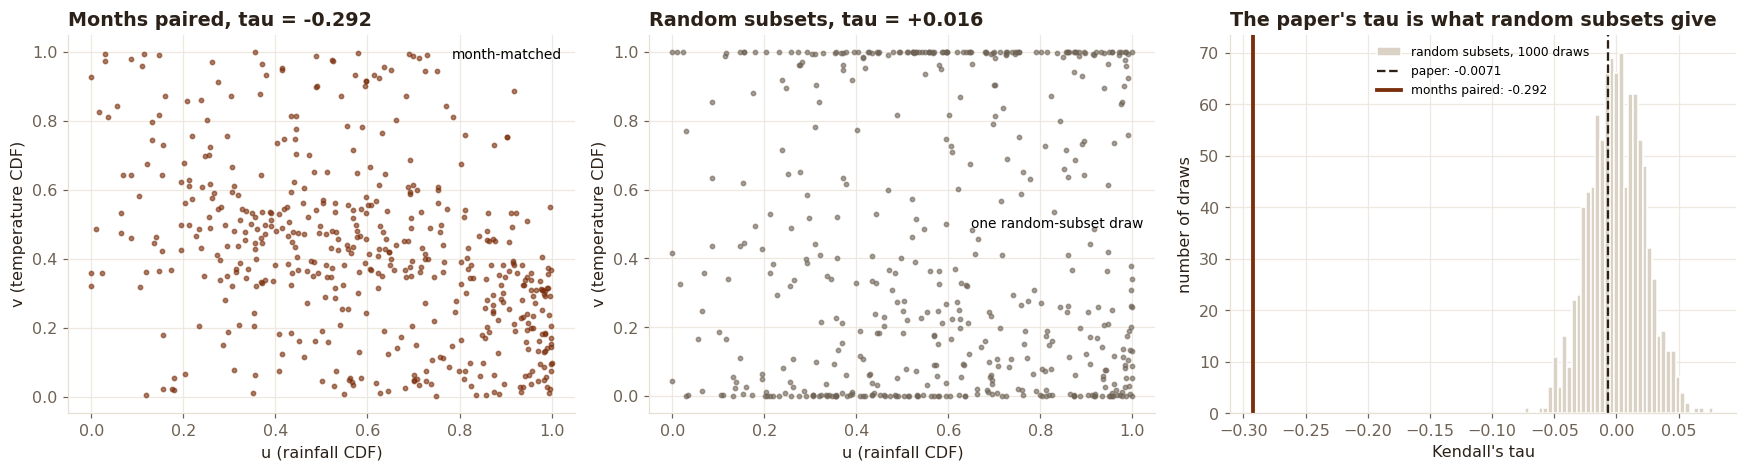

<span style='color:#6E6255'>*Same data, same marginals: only the pairing of months differs. This reproduces validation/random_subset_tau.png.*</span>

In [21]:
demo.print_authors_lines()
exp = demo.random_subset_experiment(n_draws=N_SHUFFLE)
taus = exp["taus"]

# The same effect on this district's own (u, v): shuffling destroys the pairing
rng = np.random.default_rng(1)
own = np.array([stats.kendalltau(s["u"], rng.permutation(s["v"].values)).statistic for _ in range(N_SHUFFLE)])
tab = pd.DataFrame([{"data": "paper's point, paper's parameters", "tau months paired": exp["tau_matched"],
                     "tau random subsets, mean": taus.mean(), "SD": taus.std(), "paper's reported tau": demo.PAPER_TAU},
                    {"data": f"{DISTRICT}, this model's (u, v)", "tau months paired": model.kendall_tau,
                     "tau random subsets, mean": own.mean(), "SD": own.std(), "paper's reported tau": np.nan}])
nt.show(tab, 4)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].scatter(exp["u"], exp["v_matched"], s=8, color=theme.DRY_LINE, alpha=0.6, label="month-matched")
ax[0].set_title(f"Months paired, tau = {exp['tau_matched']:+.3f}"); ax[0].set_xlabel("u (rainfall CDF)"); ax[0].set_ylabel("v (temperature CDF)"); ax[0].legend()
ax[1].scatter(exp["u"], exp["v_example"], s=8, color=theme.MUTED, alpha=0.6, label="one random-subset draw")
ax[1].set_title(f"Random subsets, tau = {stats.kendalltau(exp['u'], exp['v_example']).statistic:+.3f}")
ax[1].set_xlabel("u (rainfall CDF)"); ax[1].set_ylabel("v (temperature CDF)"); ax[1].legend()
ax[2].hist(taus, bins=40, color="#D9D2C5", edgecolor="white", label=f"random subsets, {N_SHUFFLE} draws")
ax[2].axvline(demo.PAPER_TAU, color=theme.INK, ls="--", label=f"paper: {demo.PAPER_TAU:+.4f}")
ax[2].axvline(exp["tau_matched"], color=theme.DRY_LINE, lw=2.5, label=f"months paired: {exp['tau_matched']:+.3f}")
ax[2].set_title("The paper's tau is what random subsets give"); ax[2].set_xlabel("Kendall's tau"); ax[2].set_ylabel("number of draws")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
nt.caption("Same data, same marginals: only the pairing of months differs. This reproduces validation/random_subset_tau.png.")

#### Interpretation

In [22]:
inside = np.percentile(taus, 2.5) <= demo.PAPER_TAU <= np.percentile(taus, 97.5)
nt.interpret(f"""
With months paired, tau at the paper's point is **{exp['tau_matched']:+.3f}**. Built the way `CopulaSelection.m` builds it, tau is **{taus.mean():+.4f} on average (SD {taus.std():.4f})** over {N_SHUFFLE} draws,
and the paper's {demo.PAPER_TAU:+.4f} is {'inside' if inside else 'outside'} the central 95% of those draws, while none of them comes near the paired value. The same happens with this district's data
({model.kendall_tau:+.3f} paired, {own.mean():+.4f} shuffled). This is why the paper chose weak-dependence copulas. This project pairs the months, as the paper's own equation 6 requires.
""")


With months paired, tau at the paper's point is **-0.292**. Built the way `CopulaSelection.m` builds it, tau is **+0.0004 on average (SD 0.0222)** over 1000 draws,
and the paper's -0.0071 is inside the central 95% of those draws, while none of them comes near the paired value. The same happens with this district's data
(-0.324 paired, -0.0003 shuffled). This is why the paper chose weak-dependence copulas. This project pairs the months, as the paper's own equation 6 requires.


## 10b. The direction check

$C(F_X, F_Y)$ is the probability of being dry **and cool**, but crops suffer when it is dry and hot. And because
$C(u, v) \le \min(u, v)$, a low $v$ alone gives a low $p$, so a wet cool month reads as drought too.

$$\text{dry and cool: } u<0.2,\ v<0.2\qquad\text{dry and hot: } u<0.2,\ v>0.8\qquad\text{wet and cool: } u>0.8,\ v<0.2$$

,group,months,mean MSDI-1,mean rain (mm/day),mean temperature (degC)
0,dry and hot,37,-1.68,0.35,29.83
1,dry and cool,7,-3.13,0.43,24.06
2,wet and cool,36,-1.49,9.97,24.34
3,all months,504,-1.21,3.63,27.19


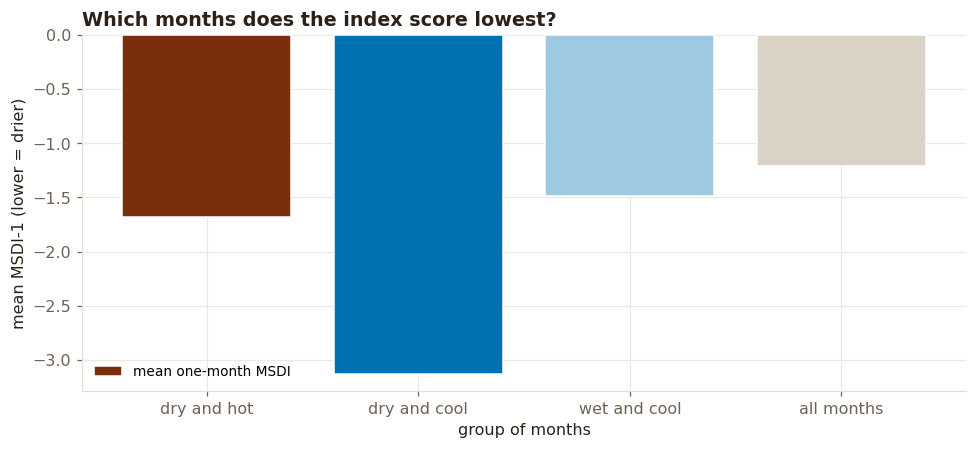

<span style='color:#6E6255'>*A drought index for crops should score dry and hot lowest, and wet and cool high.*</span>

In [23]:
dirt = mc.direction_check(model)
nt.show(dirt, 2)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(dirt["group"], dirt["mean MSDI-1"], color=[theme.DRY_LINE, theme.INDEX_COLOURS["SPI"], "#9ECAE1", "#D9D2C5"], edgecolor="white", label="mean one-month MSDI")
ax.set_title("Which months does the index score lowest?"); ax.set_xlabel("group of months"); ax.set_ylabel("mean MSDI-1 (lower = drier)"); ax.legend()
plt.tight_layout(); plt.show()
nt.caption("A drought index for crops should score dry and hot lowest, and wet and cool high.")

#### Interpretation

In [24]:
dv = dirt.set_index("group")
nt.interpret(f"""
The index scores dry and cool months at **{dv.loc['dry and cool', 'mean MSDI-1']:+.2f}**, dry and hot at **{dv.loc['dry and hot', 'mean MSDI-1']:+.2f}** and wet and cool at **{dv.loc['wet and cool', 'mean MSDI-1']:+.2f}**, against {dv.loc['all months', 'mean MSDI-1']:+.2f} for all months.
So the coolest dry months come out lowest, the reverse of what a heat-and-drought index is for, and wet cool months, with {dv.loc['wet and cool', 'mean rain (mm/day)']:.1f} mm/day of rain, still score below the average month.
There are only {int(dv.loc['dry and cool', 'months'])} dry and cool months, so that mean is uncertain, though the direction is what the formula implies.
""")


The index scores dry and cool months at **-3.13**, dry and hot at **-1.68** and wet and cool at **-1.49**, against -1.21 for all months.
So the coolest dry months come out lowest, the reverse of what a heat-and-drought index is for, and wet cool months, with 10.0 mm/day of rain, still score below the average month.
There are only 7 dry and cool months, so that mean is uncertain, though the direction is what the formula implies.


## 10c. The seasonal cycle

The marginals pool all months, so $v$ is low in every cool season whatever the weather, and $p$ follows it. This check asks
whether the index tracks droughts or the calendar.

$$\bar z_m = \frac{1}{n_m}\sum_{y} \text{MSDI}_{y,m},\qquad m = 1, \dots, 12$$

,month,mean MSDI-1,months flagged at T = 3
0,Jan,-2.34,38
1,Feb,-1.98,41
2,Mar,-1.30,41
3,Apr,-0.21,11
4,May,-0.74,4
5,Jun,-1.43,3
6,Jul,-1.38,17
7,Aug,-1.11,19
8,Sep,-0.81,6
9,Oct,-0.56,2


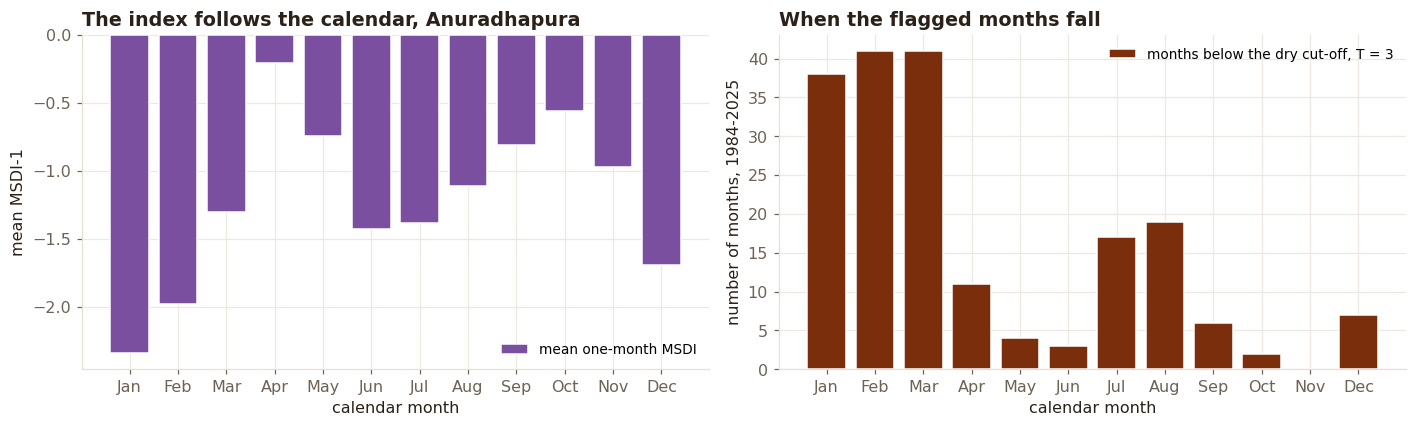

<span style='color:#6E6255'>*A drought can start in any season, so flagged months should not pile up in a few calendar months.*</span>

In [25]:
seas = mc.seasonal_check(model, T, dry)
nt.show(seas)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(seas["month"], seas["mean MSDI-1"], color=theme.INDEX_COLOURS["MSDI"], edgecolor="white", label="mean one-month MSDI")
ax[0].set_title(f"The index follows the calendar, {DISTRICT}"); ax[0].set_xlabel("calendar month"); ax[0].set_ylabel("mean MSDI-1"); ax[0].legend()
ax[1].bar(seas["month"], seas[f"months flagged at T = {T}"], color=theme.DRY_LINE, edgecolor="white", label=f"months below the dry cut-off, T = {T}")
ax[1].set_title("When the flagged months fall"); ax[1].set_xlabel("calendar month"); ax[1].set_ylabel("number of months, 1984-2025"); ax[1].legend()
plt.tight_layout(); plt.show()
nt.caption("A drought can start in any season, so flagged months should not pile up in a few calendar months.")

#### Interpretation

In [26]:
fl = seas.set_index("month")[f"months flagged at T = {T}"]
top = fl.sort_values(ascending=False).index[:3]
msd = seas.set_index("month")["mean MSDI-1"]
nt.interpret(f"""
The mean one-month MSDI runs from **{msd.min():+.2f}** in {msd.idxmin()} to **{msd.max():+.2f}** in {msd.idxmax()}, a swing of {msd.max() - msd.min():.2f} when the whole series has an SD of {s['MSDI1'].std():.2f}. The calendar month alone explains
**{100 * mc.seasonal_share(model, T):.0f}%** of the variance of MSDI-{T}, and **{100 * fl[top].sum() / max(fl.sum(), 1):.0f}%** of the flagged months fall in just three calendar months ({', '.join(top)}). So at short T the index largely picks out the cool
season, and a drought in another season has to go far below that season's own level to be seen. SPI and SSI avoid this by fitting each calendar month separately.
""")


The mean one-month MSDI runs from **-2.34** in Jan to **-0.21** in Apr, a swing of 2.13 when the whole series has an SD of 0.76. The calendar month alone explains
**65%** of the variance of MSDI-3, and **63%** of the flagged months fall in just three calendar months (Feb, Mar, Jan). So at short T the index largely picks out the cool
season, and a drought in another season has to go far below that season's own level to be seen. SPI and SSI avoid this by fitting each calendar month separately.


## 11. Agreement with SPI and SSI

Correlation, lag and dry-month overlap between the three indices, the same statistics as the dashboard's Compare page. SPI
and SSI exist at windows of 1, 3 and 6 months, so the window here is $T$ when it is one of those, otherwise 6.

$$r=\operatorname{corr}(a_t,b_t),\qquad r(k)=\operatorname{corr}(a_t,b_{t+k})$$

,pair,Pearson r,Spearman rho,best lag (months),dry in both
0,SPI-SSI,0.800,0.789,1,49
1,SPI-MSDI,0.240,0.240,0,43
2,SSI-MSDI,0.024,0.031,0,42


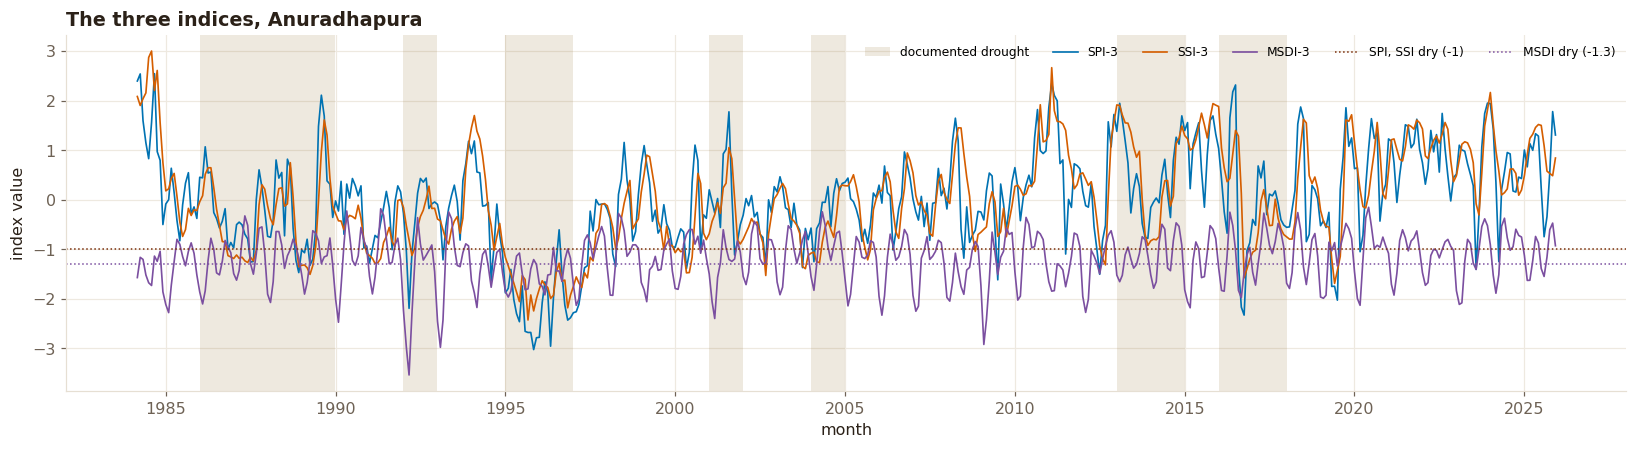

<span style='color:#6E6255'>*Shaded bands are the documented droughts. SPI and SSI fall together; MSDI runs on its own seasonal rhythm.*</span>

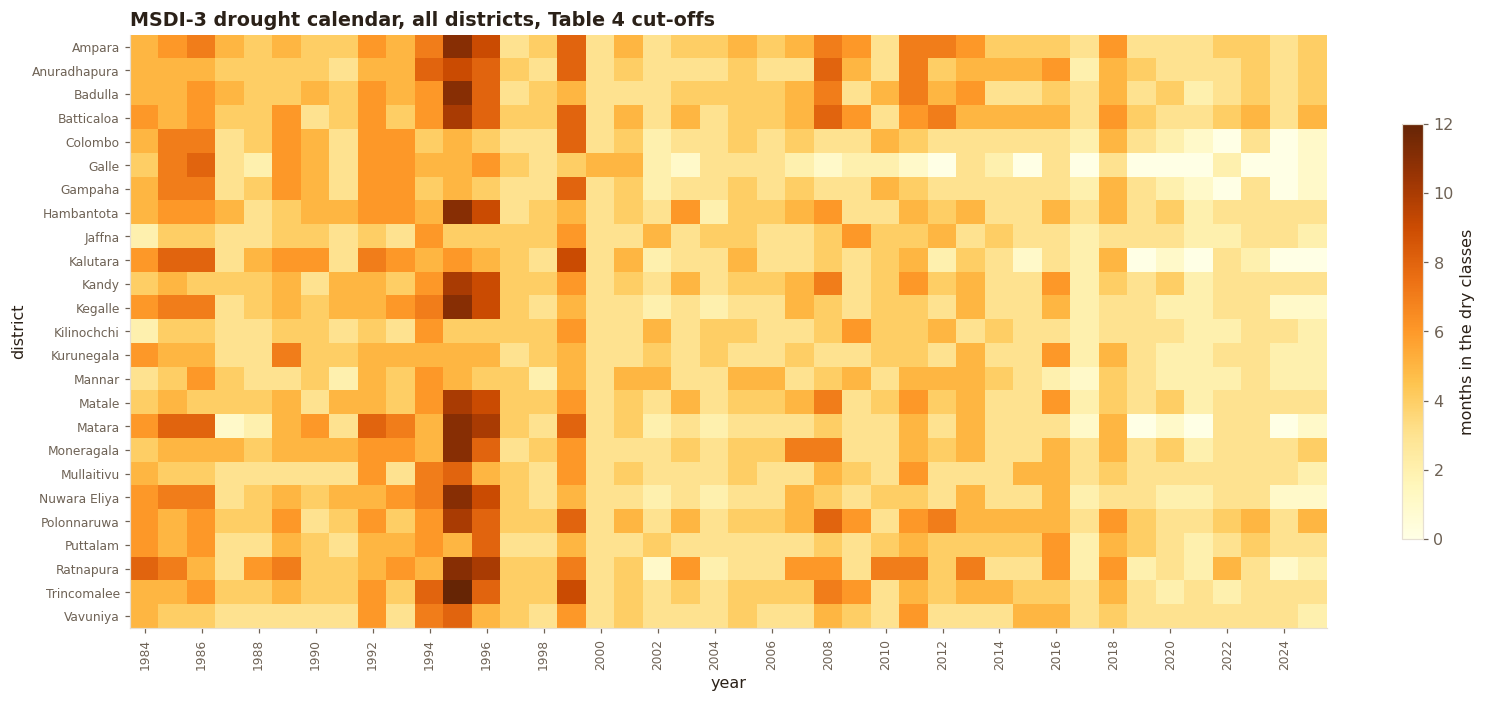

<span style='color:#6E6255'>*Darker cells have more months at or below the dry cut-off in that year.*</span>

In [27]:
W = T if T in common.SCALES else 6
dfk = CI.load_indices(DISTRICT, W)
no_season = pd.concat([dfk["SPI"], mc.without_seasons(model, W).rename("MSDI")], axis=1).dropna()
r_no_season = no_season["SPI"].corr(no_season["MSDI"])
cut = CI.dry_cutoff(W)
agree = []
for a_, b_ in CI.PAIRS:
    ps = CI.pair_stats(dfk, a_, b_, cut)
    agree.append({"pair": f"{a_}-{b_}", "Pearson r": ps[f"pearson {a_}-{b_}"], "Spearman rho": ps[f"spearman {a_}-{b_}"],
                  "best lag (months)": ps[f"best lag {a_}-{b_} (months)"], "dry in both": ps[f"dry both {a_}-{b_}"]})
agree = pd.DataFrame(agree).set_index("pair")
nt.show(agree.reset_index())

dp = dfk.reset_index(); dp["Date"] = pd.to_datetime(dp[["Year", "Month"]].assign(day=1))
dp = dp[(dp["Year"] >= START_YEAR) & (dp["Year"] <= END_YEAR)]
fig, ax = plt.subplots(figsize=(15, 4.2))
nt.shade_documented(ax)
for n in ("SPI", "SSI", "MSDI"):
    ax.plot(dp["Date"], dp[n], color=theme.INDEX_COLOURS[n], lw=1.1, label=f"{n}-{W}")
ax.axhline(-1, color=theme.DRY_LINE, ls=":", lw=1, label="SPI, SSI dry (-1)")
ax.axhline(cut, color=theme.INDEX_COLOURS["MSDI"], ls=":", lw=1, label=f"MSDI dry ({cut:g})")
ax.set_title(f"The three indices, {DISTRICT}"); ax.set_xlabel("month"); ax.set_ylabel("index value")
ax.legend(ncol=6, fontsize=8)
plt.tight_layout(); plt.show()
nt.caption("Shaded bands are the documented droughts. SPI and SSI fall together; MSDI runs on its own seasonal rhythm.")

t_ = TH.apply(index_data.load_tables()["tables"][("MSDI", T)], T)
heat = t_.groupby(["District", "Year"])["dry"].sum().unstack("Year")
fig, ax = plt.subplots(figsize=(15, 6.5))
im = ax.imshow(heat.values, aspect="auto", cmap="YlOrBr", vmin=0, vmax=12)
ax.set_yticks(range(len(heat)), heat.index, fontsize=8); ax.set_xticks(range(0, heat.shape[1], 2), heat.columns[::2], rotation=90, fontsize=8)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.7, label="months in the dry classes")
ax.set_title(f"MSDI-{T} drought calendar, all districts, Table 4 cut-offs"); ax.set_xlabel("year"); ax.set_ylabel("district")
plt.tight_layout(); plt.show()
nt.caption("Darker cells have more months at or below the dry cut-off in that year.")

#### Interpretation

In [28]:
nt.interpret(f"""
MSDI-{W} correlates with SPI at r = **{agree.loc['SPI-MSDI', 'Pearson r']:.2f}** and with SSI at r = {agree.loc['SSI-MSDI', 'Pearson r']:.2f}, while SPI and SSI correlate at {agree.loc['SPI-SSI', 'Pearson r']:.2f}. So the published MSDI shares little with the
other two. Taking out each calendar month's mean raises its correlation with SPI to **{r_no_season:.2f}**, so the seasonal cycle explains part of the gap, not all of it. A low correlation therefore does not mean
that MSDI adds information about heat. The direction problem of section 10b is the other likely part.
""")


MSDI-3 correlates with SPI at r = **0.24** and with SSI at r = 0.02, while SPI and SSI correlate at 0.80. So the published MSDI shares little with the
other two. Taking out each calendar month's mean raises its correlation with SPI to **0.41**, so the seasonal cycle explains part of the gap, not all of it. A low correlation therefore does not mean
that MSDI adds information about heat. The direction problem of section 10b is the other likely part.


# 12. Sensitivity checks

How much do the choices matter? None of these changes the index used on the dashboard.

$$\Delta_{\text{choice}} = \text{MSDI}_{\text{alternative}} - \text{MSDI}_{\text{used}}$$

## 12a. The copula family

Each usable family's index is recomputed on the same $(u, v)$ and compared with the selected one.

$$\text{MSDI}_{\text{family}} = \Phi^{-1}\big(C_{\text{family}}(u, v)\big)$$

In [29]:
base1 = s["MSDI1"]
sens = []
for f in model.copula_fits:
    if not f.usable:
        continue
    alt = mc.rescore_msdi(model, f.family, f.theta)
    sens.append({"family": f.family, "selected": "yes" if f.family == model.best_family else "", "AIC": f.aic,
                 "corr with selected": alt.corr(base1), "max abs difference": (alt - base1).abs().max(), "mean": alt.mean(),
                 f"% months below dry cut-off, T = {T}": 100 * (M.t_month_msdi(alt, T) < dry).mean()})
sens = pd.DataFrame(sens)
nt.show(sens)

,family,selected,AIC,corr with selected,max abs difference,mean,"% months below dry cut-off, T = 3"
0,Frank,yes,-121.479,1.000,0.000,-1.210,37.500
1,Gaussian,,-99.512,0.997,0.541,-1.193,35.714


#### Interpretation

In [30]:
others = sens[sens["selected"] != "yes"]
nt.interpret(f"""
The {len(others)} other usable famil{'y gives' if len(others) == 1 else 'ies give'} an index correlating at **{others['corr with selected'].min():.3f}** or more with the selected {model.best_family}, so the copula choice barely matters here, and the choice between AIC and the paper's
RMSE rule is not important. The largest change in any month is {others['max abs difference'].max():.2f}.
""")


The 1 other usable family gives an index correlating at **0.997** or more with the selected Frank, so the copula choice barely matters here, and the choice between AIC and the paper's
RMSE rule is not important. The largest change in any month is 0.54.


## 12b. T2M instead of TS

The project proposal named T2M, air temperature at 2 m. The model is refitted with it here, with no bootstrap.

$$v^{\text{T2M}} = F_{\text{T2M}}(y)\qquad\text{vs}\qquad v^{\text{TS}} = F_{\text{TS}}(y)$$

In [31]:
m2 = M.fit_msdi_model(df, DISTRICT, "t2m", n_boot=0)
comp = []
for k in TH.T_SCALES:
    a, c = s[f"MSDI{k}"], m2.series[f"MSDI{k}"]
    comp.append({"T": k, "corr TS vs T2M": a.corr(c), "mean TS": a.mean(), "mean T2M": c.mean()})
comp = pd.DataFrame(comp)
print(f"T2M model: {m2.rain.family}, {m2.best_family} (theta {m2.best_theta:.3f}), tau {m2.kendall_tau:+.3f}")
nt.show(comp)

T2M model: gamma, Frank (theta -2.743), tau -0.287


,T,corr TS vs T2M,mean TS,mean T2M
0,3,0.991,-1.208,-1.170
1,6,0.983,-1.210,-1.172
2,9,0.979,-1.209,-1.172
3,12,0.970,-1.209,-1.172


#### Interpretation

In [32]:
nt.interpret(f"""
With T2M the copula is {m2.best_family} and tau is {m2.kendall_tau:+.3f} (TS: {model.best_family}, {model.kendall_tau:+.3f}). The two T-month series correlate at **{comp['corr TS vs T2M'].min():.3f}** or more, so the choice of temperature changes
little. TS is used because it is what the paper's numbers match.
""")


With T2M the copula is Frank and tau is -0.287 (TS: Frank, -0.324). The two T-month series correlate at **0.970** or more, so the choice of temperature changes
little. TS is used because it is what the paper's numbers match.


## 13. All 25 districts

The saved summary from `run_msdi_all_districts.py` (`msdi_outputs/msdi_summary.csv`), which is what the dashboard shows.

$$\tau_d = \tau\big(u_{d,t}, v_{d,t}\big),\qquad d = 1, \dots, 25$$

,district,province,rainfall,kendall_tau,copula,theta,gof_p,usable families,MSDI1 mean,MSDI1 sd,shares_grid_cell_with
0,Ampara,Eastern,gamma,-0.372,Frank,-3.783,0.015,"Frank, Gaussian",-1.264,0.722,NaN
1,Anuradhapura,North Central,gamma,-0.324,Frank,-3.179,0.011,"Frank, Gaussian",-1.210,0.758,NaN
2,Badulla,Uva,gamma,-0.344,Frank,-3.377,0.009,"Frank, Gaussian",-1.225,0.730,NaN
3,Batticaloa,Eastern,gamma,-0.381,Frank,-3.894,0.009,"Frank, Gaussian",-1.265,0.733,Polonnaruwa
4,Colombo,Western,gamma,-0.052,Gaussian,-0.126,0.001,"Frank, FGM, AMH, Gaussian",-0.976,0.866,Gampaha
5,Galle,Southern,gamma,0.089,FGM,0.401,0.001,"Frank, FGM, AMH, Gaussian",-0.829,0.901,NaN
6,Gampaha,Western,gamma,-0.052,Gaussian,-0.126,0.001,"Frank, FGM, AMH, Gaussian",-0.976,0.866,Colombo
7,Hambantota,Southern,gamma,-0.289,Gaussian,-0.419,0.001,"Frank, Gaussian",-1.181,0.803,NaN
8,Jaffna,Northern,gamma,-0.182,FGM,-0.806,0.001,"Frank, FGM, Gaussian",-1.074,0.819,Kilinochchi
9,Kalutara,Western,gamma,-0.046,Gaussian,-0.126,0.001,"Frank, FGM, AMH, Gaussian",-0.975,0.863,NaN


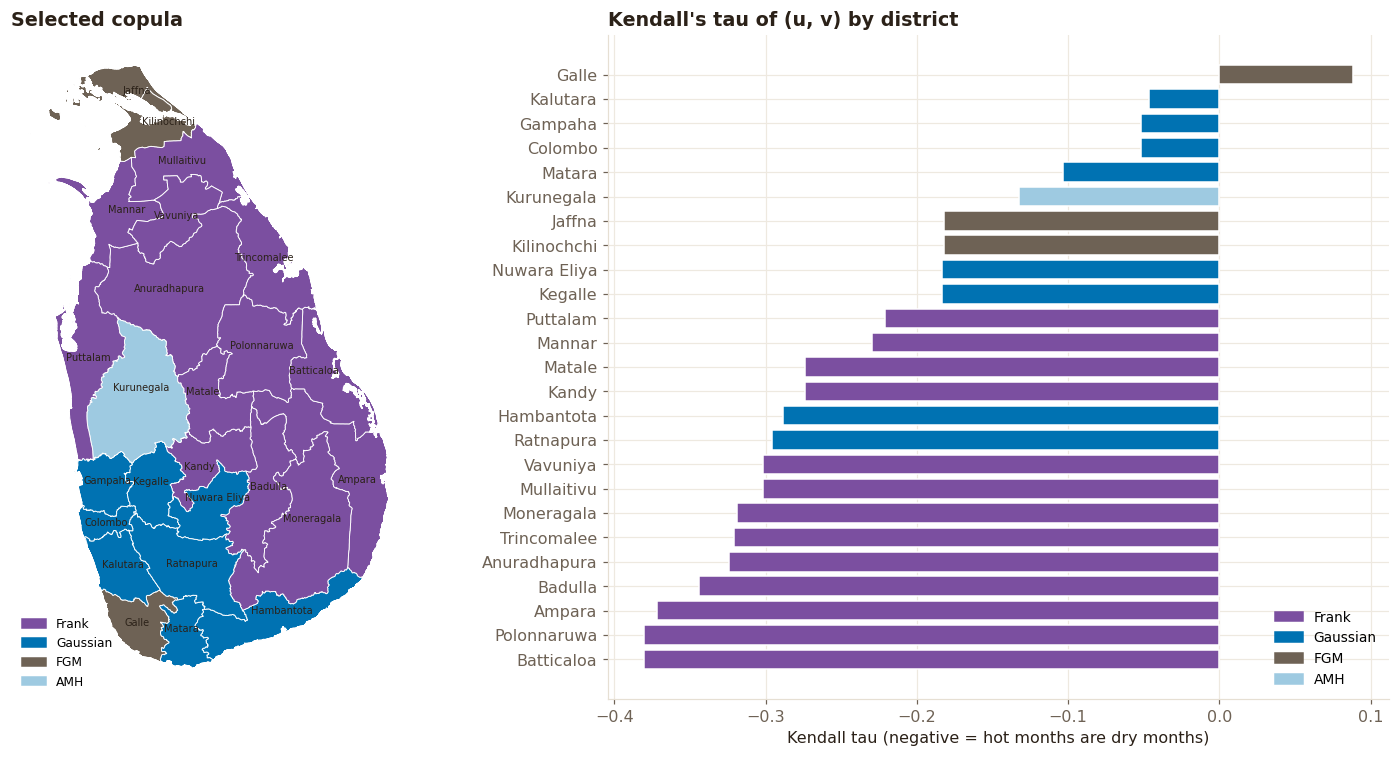

<span style='color:#6E6255'>*Colour is the selected copula; the bars show how strongly rainfall and temperature oppose each other.*</span>

In [33]:
summ = pd.read_csv("msdi_outputs/msdi_summary.csv")
nt.show(summ[["district", "province", "rainfall", "kendall_tau", "copula", "theta", "gof_p", "usable families", "MSDI1 mean", "MSDI1 sd", "shares_grid_cell_with"]], 3)
fam_c = {"Frank": theme.INDEX_COLOURS["MSDI"], "Gaussian": theme.INDEX_COLOURS["SPI"], "FGM": theme.MUTED, "AMH": "#9ECAE1",
         "Gumbel": theme.CLASS_COLOURS["Very wet"], "Clayton": theme.CLASS_COLOURS["Severely dry"]}
fig, ax = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [1, 1.2]})
nt.district_map(ax[0], summ.set_index("district")["copula"], "Selected copula", categorical=True,
                colours={k: v for k, v in fam_c.items() if k in set(summ["copula"])})
srt = summ.sort_values("kendall_tau")
ax[1].barh(srt["district"], srt["kendall_tau"], color=[fam_c.get(c, "#999") for c in srt["copula"]], edgecolor="white")
ax[1].set_title("Kendall's tau of (u, v) by district"); ax[1].set_xlabel("Kendall tau (negative = hot months are dry months)")
ax[1].legend(handles=[nt.Patch(color=v, label=k) for k, v in fam_c.items() if k in set(summ["copula"])], loc="lower right")
plt.tight_layout(); plt.show()
nt.caption("Colour is the selected copula; the bars show how strongly rainfall and temperature oppose each other.")

#### Interpretation

In [34]:
fam = summ["copula"].value_counts()
nt.interpret(f"""
The selected copula is {', '.join(f'**{k}** in {v}' for k, v in fam.items())} districts, and Gamma is the rainfall distribution in {int((summ['rainfall'] == 'gamma').sum())} of 25. Tau runs from {summ['kendall_tau'].min():+.2f} ({summ.loc[summ['kendall_tau'].idxmin(), 'district']}) to
{summ['kendall_tau'].max():+.2f} ({summ.loc[summ['kendall_tau'].idxmax(), 'district']}), weakest in the wet south-west, where temperature barely changes through the year. The mean of the one-month MSDI runs from {summ['MSDI1 mean'].min():+.2f} to
{summ['MSDI1 mean'].max():+.2f}. The test rejects the selected copula in {int((summ['gof_p'] < 0.05).sum())} of 25 districts; the method keeps the lowest AIC regardless.
""")


The selected copula is **Frank** in 13, **Gaussian** in 8, **FGM** in 3, **AMH** in 1 districts, and Gamma is the rainfall distribution in 25 of 25. Tau runs from -0.38 (Batticaloa) to
+0.09 (Galle), weakest in the wet south-west, where temperature barely changes through the year. The mean of the one-month MSDI runs from -1.26 to
-0.83. The test rejects the selected copula in 23 of 25 districts; the method keeps the lowest AIC regardless.


## 14. What this means

In [35]:
nt.interpret(f"""
**The cut-offs.** Table 4 was set on North Central Province. Used for every district, it flags {100 * sh.loc[3, 'share dry or worse']:.0f}% of months at T = 3 and {100 * sh.loc[12, 'share dry or worse']:.0f}% at T = 12 on average.

**The seasons.** The calendar month explains {100 * mc.seasonal_share(model, T):.0f}% of the variance of MSDI-{T} in {DISTRICT}, because one distribution is fitted to all months.

**The direction.** The index scores dry and cool months lowest, not dry and hot months (section 10b).
""")


**The cut-offs.** Table 4 was set on North Central Province. Used for every district, it flags 34% of months at T = 3 and 99% at T = 12 on average.

**The seasons.** The calendar month explains 65% of the variance of MSDI-3 in Anuradhapura, because one distribution is fitted to all months.

**The direction.** The index scores dry and cool months lowest, not dry and hot months (section 10b).


## 15. Summary of findings

In [36]:
nt.interpret(f"""
In {DISTRICT}, month-paired rainfall and ground temperature (TS) have Kendall's tau of {model.kendall_tau:+.3f}, and AIC selects the {model.best_family} copula, with Gamma rainfall in all 25 districts rather than the paper's Beta.
The published MSDI-{T} has mean {rw['mean']:+.2f} and SD {rw['SD']:.2f}, so it is not standardised.
Table 4 flags {100 * sh.loc[3, 'share dry or worse']:.0f}% of months at T = 3 and {100 * sh.loc[12, 'share dry or worse']:.0f}% at T = 12 on average over the 25 districts.
The direction runs the wrong way, with dry and cool months at {dv.loc['dry and cool', 'mean MSDI-1']:+.2f} ({int(dv.loc['dry and cool', 'months'])} months) and dry and hot at {dv.loc['dry and hot', 'mean MSDI-1']:+.2f}, and the paper's tau of {demo.PAPER_TAU:+.4f} is reproduced only by its unpaired random subsets ({taus.mean():+.4f} on average, against {exp['tau_matched']:+.3f} paired).
The calendar month explains {100 * mc.seasonal_share(model, T):.0f}% of the variance of MSDI-{T}.
The copula family and the temperature variable barely change the index.
""")


In Anuradhapura, month-paired rainfall and ground temperature (TS) have Kendall's tau of -0.324, and AIC selects the Frank copula, with Gamma rainfall in all 25 districts rather than the paper's Beta.
The published MSDI-3 has mean -1.21 and SD 0.51, so it is not standardised.
Table 4 flags 34% of months at T = 3 and 99% at T = 12 on average over the 25 districts.
The direction runs the wrong way, with dry and cool months at -3.13 (7 months) and dry and hot at -1.68, and the paper's tau of -0.0071 is reproduced only by its unpaired random subsets (+0.0004 on average, against -0.292 paired).
The calendar month explains 65% of the variance of MSDI-3.
The copula family and the temperature variable barely change the index.


## 16. Limitations

- **Six district pairs share one NASA cell** and have identical series: Batticaloa/Polonnaruwa, Colombo/Gampaha, Jaffna/Kilinochchi,
  Kandy/Matale, Kegalle/Nuwara Eliya, Mullaitivu/Vavuniya. Scores of such a pair are not independent.
- **Period and data.** The fit uses 1984-2025 and the paper 1981-2021, so 1982-83 cannot be tested. NASA POWER rainfall at the paper's
  point does not match its figures (maximum 20.71 against 18.41 mm/day), so Table 2 does not reproduce. The cause is not known from here.
- **Temperature.** TS matches the paper's range, though the proposal named T2M; section 12b shows it changes little.
- **Bootstrap.** 500 samples against the paper's 2000. The p-values are reported and not used.